# Naive Bayes Algorithm

Breast Cancer Classification using Naive Bayes

# Step 1: Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

# Step 2: Prepare Training and Testing Data

In [3]:
# Load dataset
df = pd.read_csv(r"C:\Users\utkri\Downloads\archive (1)\breast cancer.csv")

# Remove unnecessary columns
df = df.drop(columns=["id", "Unnamed: 32"], errors="ignore")

# Separate features and target
X = df.drop("diagnosis", axis=1)
y = df["diagnosis"].map({"M": 1, "B": 0})

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (569, 30)
Target Shape: (569,)


 # Step 3: Split Dataset

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Data: (455, 30)
Testing Data: (114, 30)
Training Target: (455,)
Testing Target: (114,)


# Step 4: Continue Naive Bayes

In [5]:
from sklearn.naive_bayes import GaussianNB

nb_model = GaussianNB()

nb_model.fit(X_train, y_train)

print("Naive Bayes Model Trained Successfully!")

Naive Bayes Model Trained Successfully!


# Step 5: Naive Bayes Model Evaluation

In [6]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Model Predictions
y_pred_nb = nb_model.predict(X_test)

# Calculate Evaluation Metrics
accuracy = accuracy_score(y_test, y_pred_nb)
precision = precision_score(y_test, y_pred_nb)
recall = recall_score(y_test, y_pred_nb)
f1 = f1_score(y_test, y_pred_nb)

# Probability Predictions
y_prob_nb = nb_model.predict_proba(X_test)[:, 1]

# ROC-AUC Score
roc_auc = roc_auc_score(y_test, y_prob_nb)

# Display Results
print("Naive Bayes Model Evaluation")
print("--------------------------------")

print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))
print("ROC-AUC  :", round(roc_auc, 4))

Naive Bayes Model Evaluation
--------------------------------
Accuracy : 0.9386
Precision: 1.0
Recall   : 0.8333
F1 Score : 0.9091
ROC-AUC  : 0.9934


# Step 6: Confusion Matrix Visualization

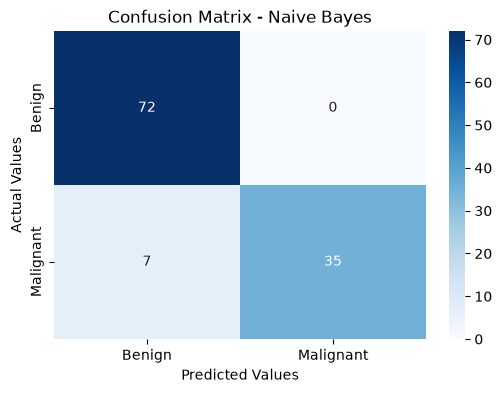

In [7]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Generate Confusion Matrix
cm = confusion_matrix(y_test, y_pred_nb)

# Visualize Confusion Matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Benign", "Malignant"],
    yticklabels=["Benign", "Malignant"]
)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("Confusion Matrix - Naive Bayes")
plt.show()

# Step 7: Classification Report

In [8]:
from sklearn.metrics import classification_report

# Generate Classification Report
report = classification_report(
    y_test,
    y_pred_nb,
    target_names=["Benign", "Malignant"]
)

print("Naive Bayes - Classification Report")
print("-----------------------------------")
print(report) 

Naive Bayes - Classification Report
-----------------------------------
              precision    recall  f1-score   support

      Benign       0.91      1.00      0.95        72
   Malignant       1.00      0.83      0.91        42

    accuracy                           0.94       114
   macro avg       0.96      0.92      0.93       114
weighted avg       0.94      0.94      0.94       114



# Step 8: ROC Curve Visualization

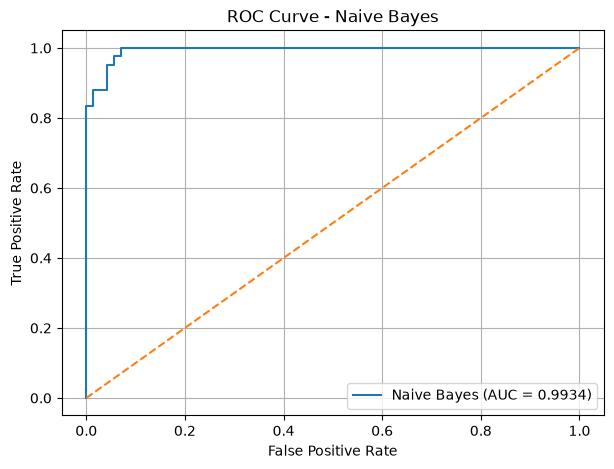

ROC-AUC Score: 0.9934


In [9]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Calculate ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob_nb)

# Calculate AUC
roc_auc = auc(fpr, tpr)

# Plot ROC Curve
plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Naive Bayes (AUC = {roc_auc:.4f})"
)

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Naive Bayes")

plt.legend()
plt.grid()
plt.show()

print("ROC-AUC Score:", round(roc_auc, 4))

# Step 9: Final Results Summary

In [10]:
# Create Final Results DataFrame

results_nb = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})

# Display Final Results
print("NAIVE BAYES - FINAL RESULTS")
print("=" * 40)

print(results_nb.to_string(index=False))

NAIVE BAYES - FINAL RESULTS
   Metric    Score
 Accuracy 0.938596
Precision 1.000000
   Recall 0.833333
 F1 Score 0.909091
  ROC-AUC 0.993386


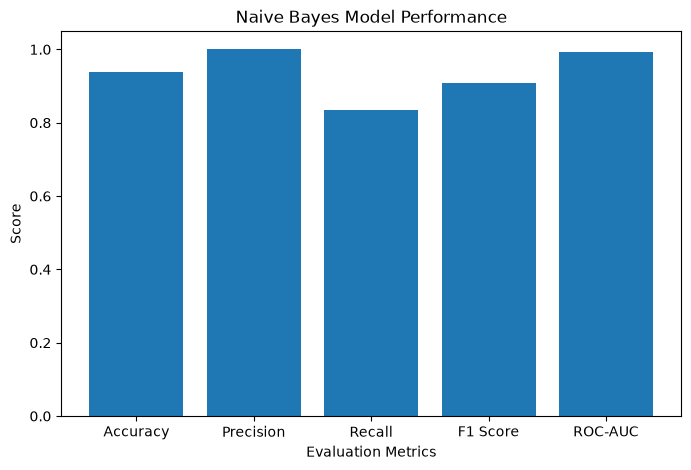

In [11]:
plt.figure(figsize=(8, 5))

plt.bar(
    results_nb["Metric"],
    results_nb["Score"]
)

plt.ylim(0, 1.05)
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.title("Naive Bayes Model Performance")

plt.show()

# Conclusion

The Gaussian Naive Bayes algorithm was successfully implemented for breast cancer classification. The model uses probability-based classification to distinguish between Benign and Malignant tumor cases.

The experiment demonstrates the application of Bayes' theorem in supervised machine learning and highlights the importance of evaluating classification models using multiple performance metrics.

The model's effectiveness should be assessed using its actual test results, particularly the recall for the Malignant class. This project is intended for educational and research purposes and is not a clinically validated diagnostic system.